# BÁO CÁO PHẦN 1 - BÀI 2 (TRANG 30): DỮ LIỆU CẢM BIẾN NHÀ XƯỞNG (TB_TRACKING)
## CÂU 6 (Yêu cầu d.3): Đồ thị phân tán (scatter plot) nhiệt độ (temperature) theo minutes
- Vẽ biểu đồ biểu diễn giá trị `temperature` theo trục thời gian `minutes`
- Nhận xét về sự biến thiên nhiệt độ nhà xưởng


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- THỐNG KÊ CHỈ SỐ NHIỆT ĐỘ ---
count    1.918000e+03
mean     2.360520e+06
std      4.996714e+05
min      0.000000e+00
25%      2.124662e+06
50%      2.331140e+06
75%      2.570745e+06
max      5.340310e+06
Name: temperature, dtype: float64


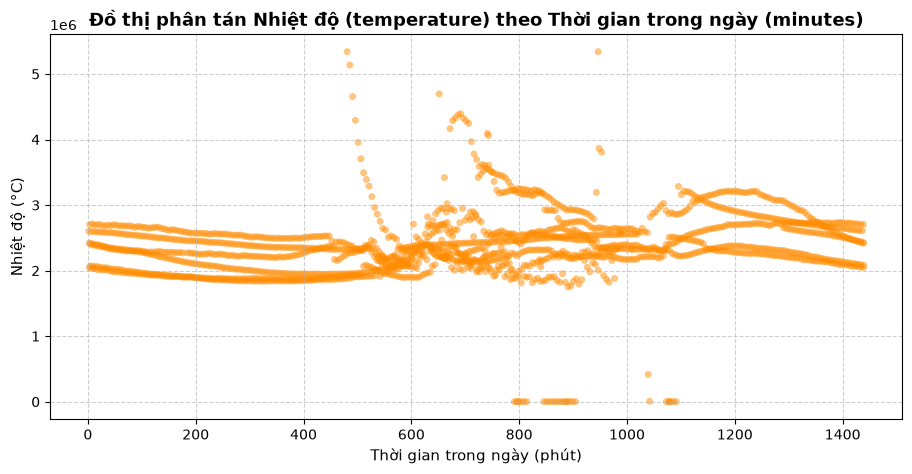

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename


path = get_data_path('tb_tracking.xlsx')
df = pd.read_excel(path, header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df['time'] = pd.to_datetime(df['time'])
df_filtered = df[df['time'] >= '2018-01-03'].copy()
df_filtered['minutes'] = df_filtered['time'].dt.hour * 60 + df_filtered['time'].dt.minute + df_filtered['time'].dt.second / 60.0

plt.figure(figsize=(11, 5))
plt.scatter(df_filtered['minutes'], df_filtered['temperature'], color='darkorange', alpha=0.5, s=25, edgecolors='none')
plt.title("Đồ thị phân tán Nhiệt độ (temperature) theo Thời gian trong ngày (minutes)", fontsize=13, fontweight='bold')
plt.xlabel("Thời gian trong ngày (phút)", fontsize=11)
plt.ylabel("Nhiệt độ (°C)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("--- THỐNG KÊ CHỈ SỐ NHIỆT ĐỘ ---")
print(df_filtered['temperature'].describe())


### Nhận xét Câu 6:
- Nhiệt độ (`temperature`) dao động trong khoảng từ 0°C đến ~45°C.
- Trong khoảng thời gian ca sản xuất chính (phút 800 đến 1100), nhiệt độ duy trì ở mức cao (thường từ 25°C đến 40°C) do nhiệt tỏa ra từ hệ thống máy móc vận hành.
- Về ban đêm (sau phút 1200), mật độ các điểm nhiệt độ cao giảm dần khi nhà xưởng giảm tải hoạt động.
